In [1]:
import urllib.request
import PIL
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, losses

imgURL = "https://raw.githubusercontent.com/larvalabs/cryptopunks/master/punks.png"
urllib.request.urlretrieve(imgURL, "cryptoPunksAll.jpg")
img = PIL.Image.open("cryptoPunksAll.jpg").convert("RGB")
imgArray = np.asarray(img)

n = 10000

finalArray = np.empty((n, 24, 24, 3))
for i in range(100):
  for j in range(100):
    a, b = 24 * i, 24 * (i + 1)
    c, d = 24 * j, 24 * (j + 1)
    idx = j + i * (100)
    finalArray[idx,:,:,:] = imgArray[a:b,c:d,:]

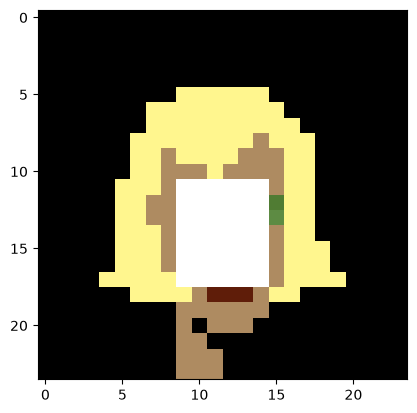

In [2]:
temp  =  finalArray[0,:,:,:].copy()

d2min, d2max = 9,14
d1min, d1max = 11,17

temp[d1min : (d1max + 1), d2min : (d2max + 1)] = 255

plt.imshow(temp.astype('uint8'))

In [3]:
cancerpunks = finalArray.copy()
label = np.zeros(n)

for i in range(10000):
  flip = np.random.randint(0, 2)
  if flip == 1:
    label[i] = 1
    d1loc = np.random.randint(d1min, d1max + 1)
    d2loc = np.random.randint(d2min, d2max + 1)
    cancerpunks[i,d1loc,d2loc,:] = 255

In [4]:
print(label.sum(), "out of", len(label), "punks marked diseased")

4994.0 out of 10000 punks marked diseased


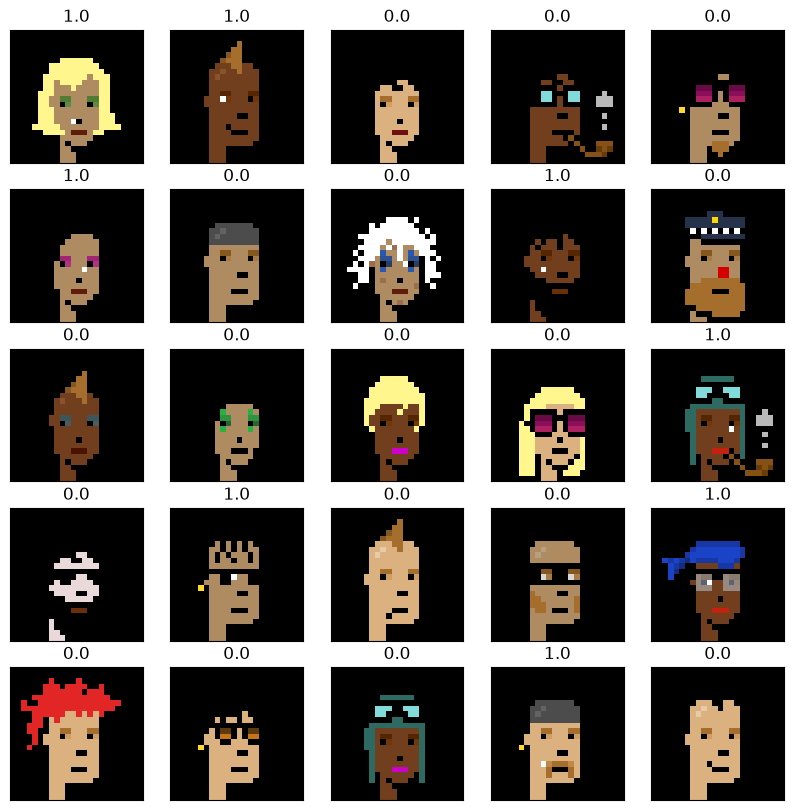

In [5]:
plt.figure(figsize=(10,10))
for i in range(25):
  plt.subplot(5,5,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.imshow(cancerpunks[i,:,:,:].astype('uint8'))
  plt.title(label[i])

In [6]:
x_all = cancerpunks / 255
y_all = label

In [7]:
n = x_all.shape[0]
trainFraction = 0.8

np.random.seed(0)  
sample = np.random.uniform(size=n) < trainFraction

x_train = x_all[sample, :, :, :]
x_val   = x_all[~sample, :, :, :]

y_train = y_all[sample]
y_val   = y_all[~sample]

print(x_train.shape, x_val.shape)

(8028, 24, 24, 3) (1972, 24, 24, 3)


In [8]:
model = models.Sequential([
    layers.Input(shape=(24, 24, 3)),
    layers.Conv2D(16, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 22, 22, 16)          │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 11, 11, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 9, 9, 32)            │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 4, 4, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │          16,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 21,537 (84.13 KB)

 Trainable params: 21,537 (84.13 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model.compile(
    optimizer='adam',
    loss=losses.BinaryCrossentropy(),
    metrics=['accuracy']
)

history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=10,
    batch_size=32
)

Epoch 1/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.5967 - loss: 0.6635 - val_accuracy: 0.7272 - val_loss: 0.5493
Epoch 2/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.8530 - loss: 0.3528 - val_accuracy: 0.9016 - val_loss: 0.2387
Epoch 3/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9260 - loss: 0.1891 - val_accuracy: 0.9153 - val_loss: 0.1870
Epoch 4/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9454 - loss: 0.1305 - val_accuracy: 0.9371 - val_loss: 0.1356
Epoch 5/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9543 - loss: 0.1036 - val_accuracy: 0.9478 - val_loss: 0.1130
Epoch 6/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9596 - loss: 0.0900 - val_accuracy: 0.9650 - val_loss: 0.0934
Epoch 7/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9664 - loss: 0.0754 - val_accuracy: 0.9650 - val_loss: 0.0835
Epoch 8/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9718 - loss: 0.0661 - val_accu

In [10]:
from sklearn.metrics import confusion_matrix

def evaluate_model(x, y_true):
    probs = model.predict(x)
    y_pred = (probs > 0.5).astype(int).flatten()
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    accuracy    = (tp + tn) / (tp + tn + fp + fn)
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    return accuracy, sensitivity, specificity

train_acc, train_sens, train_spec = evaluate_model(x_train, y_train)
val_acc,   val_sens,   val_spec   = evaluate_model(x_val, y_val)

print("Training set")
print("  accuracy:   ", train_acc)
print("  sensitivity:", train_sens)
print("  specificity:", train_spec)

print("Validation set")
print("  accuracy:   ", val_acc)
print("  sensitivity:", val_sens)
print("  specificity:", val_spec)

251/251 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
Training set
  accuracy:    0.9879172894867962
  sensitivity: 0.9825523429710867
  specificity: 0.9932768924302788
Validation set
  accuracy:    0.9771805273833671
  sensitivity: 0.9684317718940937
  specificity: 0.9858585858585859


## Contrasting training vs. validation performance

The model reached 98.8% accuracy on the training set and 97.7% on the validation set. Specificity was higher than sensitivity on both sets (99.3% vs. 98.3% for training and 98.6% vs. 96.8% for validation). This means the model was slightly better at identifying healthy punks than diseased ones.

The training results were slightly better than the validation results, but the differences were small. This suggests the model is performing well on new images without too much overfitting. The lower sensitivity means that some diseased punks were incorrectly classified as healthy.

## Generative AI Use
Claude AI used to identify warnings populated in the notebook in cells 3 and 8. Cell 3 was identified as differences in python formats between Colab and Jupyter Notebook. Cell 8 was Keras warning me to use a different syntax preferred by a newer version of Keras. The AI tool helped me to improve the coding to remove the warnings, but did not substantially change the code. It also helped me to learn how to improve the code in the model evaluation to simplify the evaluation and make it easier to understand. 